In [1]:
import os
import sys

# Đường dẫn thư mục dự án trên Google Drive
drive_dir = '/content/drive/MyDrive/csttnt_nang_cao/lab05_game'

# Kiểm tra xem có đang chạy trên Google Colab hay không
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    if os.path.exists(drive_dir):
        os.chdir(drive_dir)
    else:
        print(f"Cảnh báo: Không tìm thấy thư mục {drive_dir}")
else:
    # Nếu chạy ở máy cục bộ (Local Python), chuyển về thư mục chứa file code hiện tại
    script_dir = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
    os.chdir(script_dir)

print("Thư mục hiện tại:", os.getcwd())
# print("Danh sách file:", os.listdir(os.getcwd()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục hiện tại: /content/drive/MyDrive/csttnt_nang_cao/lab05_game


# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [2]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [3]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [4]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)

    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))

            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")

            print("Please enter a valid move.")


    return(move)

In [5]:
from IPython.display import clear_output
import time

def interactive_player(board, player = None):
    clear_output(wait = True)
    show_board(board, help = True)

    available = actions(board)
    print(f'Available actions are: {available}')

    time.sleep(0.3)

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))

            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")

            print("Please enter a valid move.")


    return(move)

## Start an interactive game as x

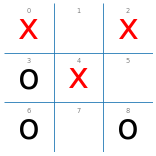

Available actions are: [1, 5, 7]
Your move (0-8 or -1 to end the game):
1


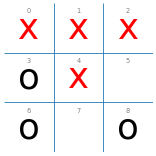

{'x': 1, 'o': 0, 'd': 0}

In [6]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

### Start an interactive game as o

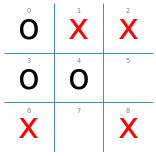

Available actions are: [5, 7]
Your move (0-8 or -1 to end the game):
5


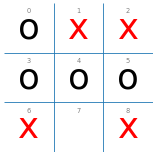

{'x': 0, 'o': 1, 'd': 0}

In [7]:
play(random_player, interactive_player, N = 1, show_final_board = True)

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
import math
import time

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)

    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)

        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)

        # switch between players
        current_player = other(current_player)

def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG

    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")

    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)

    action = max(ps, key=ps.get)
    return action

def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action

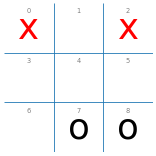

Available actions are: [1, 3, 4, 5, 6]
Your move (0-8 or -1 to end the game):
1


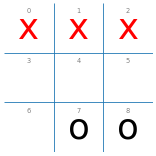

{'x': 1, 'o': 0, 'd': 0}

In [11]:
# Đảm bảo đã import hàm interactive_player từ tictactoe_interactive.ipynb
# và pmcs100_player từ phần Monte Carlo Search

DEBUG = 0 # Tắt log debug của PMCS để giao diện sạch đẹp

# THỦ BƯỚC 1: Bạn đóng vai X (đi trước), PMCS (N=100) đóng vai O (đi sau)
print("=== VÁN 1: BẠN (X) ĐẤU VỚI PMCS (O) ===")
play(interactive_player, pmcs100_player, N=1, show_final_board=True)

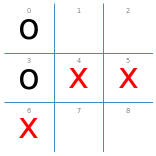

Available actions are: [1, 2, 7, 8]
Your move (0-8 or -1 to end the game):
1


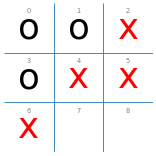

{'x': 1, 'o': 0, 'd': 0}

In [10]:
# THỦ BƯỚC 2: PMCS (N=100) đóng vai X (đi trước), Bạn đóng vai O (đi sau)
print("=== VÁN 2: PMCS (X) ĐẤU VỚI BẠN (O) ===")
play(pmcs100_player, interactive_player, N=1, show_final_board=True)